Зчитуємо дані з: processed_rozetka_reviews.csv

Автор           | Polarity | Тональність
Юра М***        | 1.0      | Позитивний
Сергей Б***     | 0.38     | Позитивний
Владислав П***  | 1.0      | Позитивний
Дмитро          | 0.12     | Позитивний
Антон М***      | 0.46     | Позитивний
Аліна П***      | 0.06     | Нейтральний


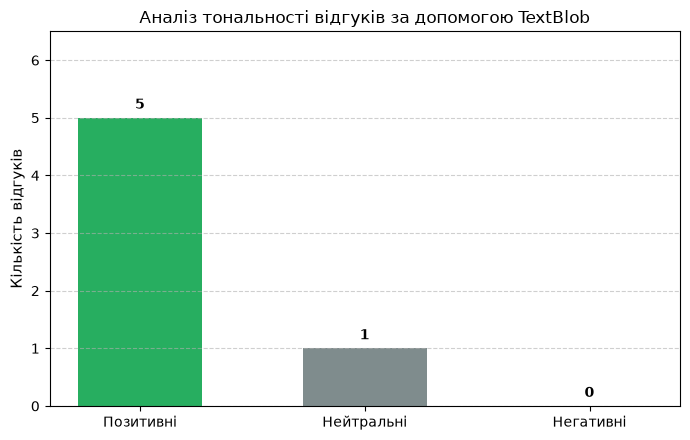

In [2]:
import glob
import json
import os
import matplotlib.pyplot as plt
import pandas as pd
from textblob import TextBlob

# Автоматичний пошук CSV-файлу від Rozetka у поточній папці
# In Jupyter Notebook, __file__ is not defined, so use the current working directory
current_dir = os.getcwd()
csv_files = glob.glob(os.path.join(current_dir, "*rozetka*.csv"))

if not csv_files:
    raise FileNotFoundError("CSV-файл з відгуками Rozetka не знайдено!")

input_csv = csv_files[0]
print(f"Зчитуємо дані з: {os.path.basename(input_csv)}")
df = pd.read_csv(input_csv)

# Словник швидкого перекладу для отриманих відгуків (щоб не залежати від зовнішніх API)
translations = {
    "Смачний": "Delicious",
    "Просто топ!!!! Це був останній з лінійки Егерів , тому прийшлося пробувати:)))": "Just top! It was the last of the Jagermeister line, so had to try it :)))",
    "Чудовий": "Wonderful",
    "З оф сайту знайшов, що треба пити разом з тоніком і це відкрило весь потенціал даного напою\nСпочатку спробував його просто охолодженим і здалось ніби простий, трохи гіркіший, єгерь з нотками кави\nАле банально додавання швепсу 1 до 1 явно підкреслює смак кави\nОднозначно рекомендую": "Found from official site to drink with tonic and this opened full potential. Definitely recommend.",
    "Оригінальний смак із нотками кави, любителі точного зацінять, на мій погляд цікавіше маніфеста, раджу)": "Original taste with coffee notes, lovers will appreciate, in my opinion more interesting, I recommend.",
    "Лікер непоганий, смачний.\nНа смак як звичайний класичний Єгер, в кінці відчувається гірчинка кави. На запах щось змішане між класичним єгерем і кавою.": "Not bad liqueur, tasty. Tastes like classic Jager with subtle coffee bitterness.",
}

# Спроба підключити онлайн-перекладач для будь-яких нових відгуків
try:
    from deep_translator import GoogleTranslator

    translator = GoogleTranslator(source="auto", target="en")
except Exception:
    translator = None

results = []
sentiments = []

for idx, row in df.iterrows():
    text = str(row["Comment Text"]).strip()
    author = row.get("Author", f"Користувач {idx + 1}")

    # 1. Переклад тексту для TextBlob
    if text in translations:
        text_en = translations[text]
    elif translator:
        try:
            text_en = translator.translate(text)
        except Exception:
            text_en = text
    else:
        text_en = text

    # 2. ВИКОРИСТАННЯ TEXTBLOB
    blob = TextBlob(text_en)
    polarity = blob.sentiment.polarity  # Число від -1.0 (негатив) до +1.0 (позитив)

    # 3. Класифікація тональності
    if polarity > 0.1:
        sentiment = "Позитивний"
    elif polarity < -0.1:
        sentiment = "Негативний"
    else:
        sentiment = "Нейтральний"

    sentiments.append(sentiment)
    results.append(
        {
            "Author": author,
            "Comment Text": text,
            "Polarity (TextBlob)": round(polarity, 2),
            "Sentiment": sentiment,
        }
    )

# 4. Виведення результатів аналізу в консоль
print("\n" + "=" * 55)
print(f"{'Автор':<15} | {'Polarity':<8} | {'Тональність'}")
print("=" * 55)
for r in results:
    print(
        f"{r['Author']:<15} | {r['Polarity (TextBlob)']:<8} | {r['Sentiment']}"
    )

# 5. Підрахунок кількості кожного типу відгуків
counts = {
    "Позитивні": sentiments.count("Позитивний"),
    "Нейтральні": sentiments.count("Нейтральний"),
    "Негативні": sentiments.count("Негативний"),
}

# 6. Побудова діаграми
plt.figure(figsize=(7, 4.5))
colors = ["#27ae60", "#7f8c8d", "#e74c3c"]
bars = plt.bar(counts.keys(), counts.values(), color=colors, width=0.55)

plt.title("Аналіз тональності відгуків за допомогою TextBlob", fontsize=12)
plt.ylabel("Кількість відгуків", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.6)

for bar in bars:
    y_val = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        y_val + 0.1,
        str(int(y_val)),
        ha="center",
        va="bottom",
        fontweight="bold",
    )

plt.ylim(0, max(counts.values()) + 1.5)
plt.tight_layout()
plt.show()